In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))   # make `src` importable when running from notebooks/
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
from src.utils import *
from src.experiments import MULTI_SCORING, run_experiment, show, multiclass_metrics

# Challenge 2 - Multiclass baseline (mel / bcc / scc)
Three classes of malignant lesions: **melanoma (0)**, **basal cell carcinoma (1)** and **squamous cell carcinoma (2)**.
The training set is imbalanced: about 53% mel, 39% bcc and only 7% scc.

The multiclass images are the same files as the mel/bcc/scc images of the binary `others` class, so they are already preprocessed
and their 230 features already extracted. `python -m src.generate_multiclass_features` only filters those rows of the binary feature CSVs
and relabels them (no new preprocessing or extraction).

As in the binary problem, models are compared with **5-fold CV on train only**; the validation set is used once at the end.

## 1. Check of the multiclass data
Number of images per class in train and validation:

In [2]:
gt_train, gt_val = pd.read_csv(MULTI_GT_TRAIN_CSV), pd.read_csv(MULTI_GT_VAL_CSV)
train, val = pd.read_csv(MULTI_FEATURES_TRAIN_CSV), pd.read_csv(MULTI_FEATURES_VAL_CSV)

counts = pd.DataFrame({
    "train": train["label"].map(MULTI_CLASS_NAMES).value_counts(),
    "val":   val["label"].map(MULTI_CLASS_NAMES).value_counts(),
}).loc[list(MULTI_CLASS_NAMES.values())]
counts["train %"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts["val %"]   = (100 * counts["val"] / counts["val"].sum()).round(1)
counts.loc["total"] = counts.sum().round(1)
counts

,train,val,train %,val %
label,,,,
mel,2713.0,678.0,53.4,53.4
bcc,1993.0,498.0,39.2,39.2
scc,376.0,94.0,7.4,7.4
total,5082.0,1270.0,100.0,100.0


The features must belong to exactly the images of the ground truth, and the filename prefix (`mel`, `bcc`, `scc`) must match the class:

In [3]:
prefix = lambda df: df["filename"].str.replace(r"\d+\.jpg$", "", regex=True)
for name, gt, feats in [("train", gt_train, train), ("val", gt_val, val)]:
    same_images = feats["filename"].tolist() == gt["filename"].tolist()
    same_labels = (feats["label"] == gt["label"]).all()
    prefix_ok = (prefix(feats) == feats["label"].map(MULTI_CLASS_FOLDERS)).all()
    print(f"{name}: {len(feats)} images | same images as ground truth: {same_images} | same labels: {same_labels} | prefix matches class: {prefix_ok}")

feature_cols = [c for c in train.columns if c not in ("filename", "label")]
print("Features:", len(feature_cols), "| NaN in train/val:", train[feature_cols].isna().sum().sum(), val[feature_cols].isna().sum().sum())

train: 5082 images | same images as ground truth: True | same labels: True | prefix matches class: True
val: 1270 images | same images as ground truth: True | same labels: True | prefix matches class: True
Features: 230 | NaN in train/val: 0 0


Visual check: 9 random training images, loaded from the multiclass folders. The title shows the filename and the class given by its label;
the prefix of the filename must be the same as the class.

seed: 716


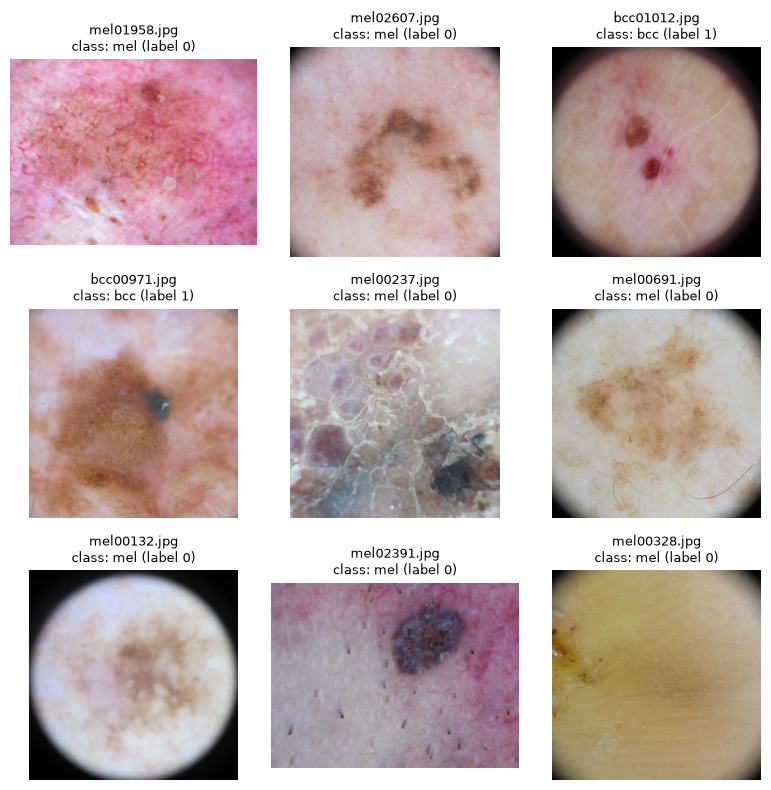

In [4]:
sample = random_sample(gt_train, n=9)
images = [load_image(r.filename, r.label, MULTI_TRAIN_DIR, MULTI_CLASS_FOLDERS) for r in sample.itertuples()]
titles = [f"{r.filename}\nclass: {MULTI_CLASS_NAMES[r.label]} (label {r.label})" for r in sample.itertuples()]
show_grid(images, titles)

## 2. Cross-validation on train: 6 models, with and without class weights
Same 6 models and search spaces as in `baseline-classification.ipynb` (SVM, XGBoost and CatBoost tuned with `RandomizedSearchCV`,
best configuration chosen by **balanced accuracy**). Two versions:
- **no weighting**: every image counts the same, so the models are pushed towards mel and bcc.
- **balanced weights**: each image is weighted by 1 / frequency of its class, so the 376 scc weigh as much as the 2713 mel.

Metrics: accuracy, balanced accuracy (mean recall of the 3 classes), Cohen's kappa, macro F1, and the recall of each class.

In [5]:
X, y = train[feature_cols].values, train["label"].values
X_val, y_val = val[feature_cols].values, val["label"].values

res_plain, fitted_plain = run_experiment("no weighting", X, y, scoring=MULTI_SCORING)
res_bal, fitted_bal = run_experiment("balanced weights", X, y, scoring=MULTI_SCORING, balanced=True)

[no weighting] LogReg: balanced acc = 0.619


[no weighting] Random Forest: balanced acc = 0.598


[no weighting] HistGradBoost: balanced acc = 0.635


[no weighting] SVM (RBF): balanced acc = 0.709


[no weighting] XGBoost: balanced acc = 0.650


...

[balanced weights] Random Forest: balanced acc = 0.649


[balanced weights] HistGradBoost: balanced acc = 0.666


[balanced weights] SVM (RBF): balanced acc = 0.733


[balanced weights] XGBoost: balanced acc = 0.691


[balanced weights] CatBoost: balanced acc = 0.694


In [6]:
cv_results = pd.concat([res_plain, res_bal], ignore_index=True)
cv_results.to_csv(RESULTS_DIR / "multi_cv_baseline.csv", index=False)
show(cv_results, MULTI_SCORING)

,experiment,model,accuracy,balanced_accuracy,kappa,f1_macro,recall_mel,recall_bcc,recall_scc
0,no weighting,LogReg,0.804 ± 0.013,0.619 ± 0.023,0.636 ± 0.023,0.626 ± 0.029,0.876 ± 0.022,0.828 ± 0.022,0.152 ± 0.054
1,no weighting,Random Forest,0.818 ± 0.006,0.598 ± 0.004,0.658 ± 0.011,0.586 ± 0.009,0.897 ± 0.012,0.859 ± 0.016,0.037 ± 0.017
2,no weighting,HistGradBoost,0.830 ± 0.006,0.635 ± 0.011,0.683 ± 0.010,0.645 ± 0.019,0.899 ± 0.015,0.867 ± 0.017,0.138 ± 0.046
3,no weighting,SVM (RBF),0.849 ± 0.008,0.709 ± 0.010,0.720 ± 0.015,0.736 ± 0.014,0.923 ± 0.013,0.838 ± 0.022,0.367 ± 0.054
4,no weighting,XGBoost,0.830 ± 0.010,0.650 ± 0.013,0.685 ± 0.017,0.667 ± 0.022,0.901 ± 0.022,0.853 ± 0.016,0.197 ± 0.053
5,no weighting,CatBoost,0.827 ± 0.006,0.634 ± 0.014,0.678 ± 0.010,0.645 ± 0.020,0.901 ± 0.014,0.856 ± 0.017,0.146 ± 0.039
6,balanced weights,LogReg,0.745 ± 0.005,0.694 ± 0.014,0.572 ± 0.008,0.645 ± 0.008,0.806 ± 0.013,0.693 ± 0.020,0.582 ± 0.043
7,balanced weights,Random Forest,0.813 ± 0.012,0.649 ± 0.010,0.657 ± 0.020,0.666 ± 0.014,0.856 ± 0.020,0.867 ± 0.016,0.226 ± 0.033
8,balanced weights,HistGradBoost,0.833 ± 0.010,0.666 ± 0.008,0.691 ± 0.017,0.687 ± 0.013,0.887 ± 0.021,0.871 ± 0.019,0.242 ± 0.042
9,balanced weights,SVM (RBF),0.805 ± 0.007,0.733 ± 0.014,0.661 ± 0.009,0.703 ± 0.010,0.857 ± 0.022,0.780 ± 0.012,0.564 ± 0.047


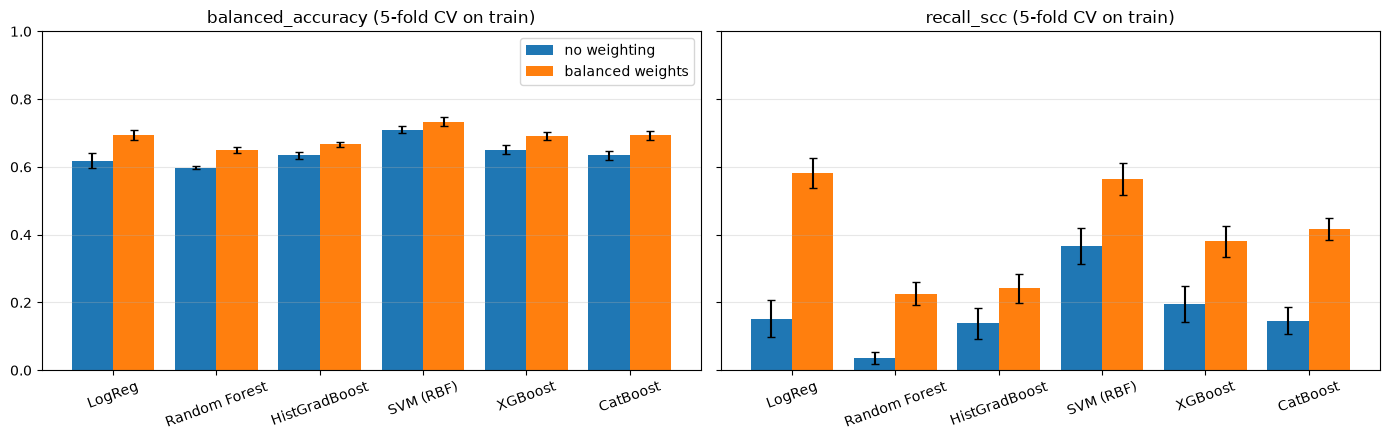

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
models = res_plain["model"].tolist()
x = np.arange(len(models))
for ax, metric in zip(axes, ["balanced_accuracy", "recall_scc"]):
    for offset, (exp, res) in zip([-0.2, 0.2], [("no weighting", res_plain), ("balanced weights", res_bal)]):
        ax.bar(x + offset, res[metric], width=0.4, yerr=res[f"{metric}_std"], capsize=3, label=exp)
    ax.set_xticks(x, models, rotation=20)
    ax.set_title(f"{metric} (5-fold CV on train)")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

## 3. Evaluation on the validation set
The best model is chosen **by CV balanced accuracy** (never by the validation score). The validation results of all 12 models are shown only to analyse them.

In [8]:
fitted = {("no weighting", m): model for m, model in fitted_plain.items()}
fitted |= {("balanced weights", m): model for m, model in fitted_bal.items()}
predictions = {key: model.predict(X_val) for key, model in fitted.items()}

val_results = pd.DataFrame([{"experiment": exp, "model": m, **multiclass_metrics(y_val, y_pred)}
                            for (exp, m), y_pred in predictions.items()])
val_results.to_csv(RESULTS_DIR / "multi_val_baseline.csv", index=False)

cv_bacc = cv_results.set_index(["experiment", "model"])["balanced_accuracy"]
val_results.insert(2, "cv_balanced_accuracy", cv_bacc.loc[list(zip(val_results["experiment"], val_results["model"]))].values)
val_results.round(3)

,experiment,model,cv_balanced_accuracy,accuracy,balanced_accuracy,kappa,f1_macro,recall_mel,recall_bcc,recall_scc
0,no weighting,LogReg,0.619,0.801,0.635,0.631,0.652,0.860,0.831,0.213
1,no weighting,Random Forest,0.598,0.817,0.611,0.657,0.613,0.885,0.863,0.085
2,no weighting,HistGradBoost,0.635,0.840,0.651,0.702,0.667,0.903,0.882,0.170
3,no weighting,SVM (RBF),0.709,0.859,0.732,0.741,0.757,0.919,0.861,0.415
4,no weighting,XGBoost,0.650,0.846,0.670,0.714,0.688,0.906,0.882,0.223
5,no weighting,CatBoost,0.634,0.835,0.649,0.691,0.667,0.906,0.861,0.181
6,balanced weights,LogReg,0.694,0.730,0.702,0.549,0.641,0.782,0.675,0.649
7,balanced weights,Random Forest,0.649,0.816,0.666,0.663,0.681,0.853,0.867,0.277
8,balanced weights,HistGradBoost,0.666,0.836,0.678,0.698,0.698,0.892,0.865,0.277
9,balanced weights,SVM (RBF),0.733,0.811,0.750,0.670,0.718,0.858,0.785,0.606


Confusion matrices on validation of the best model of each version (chosen by CV):

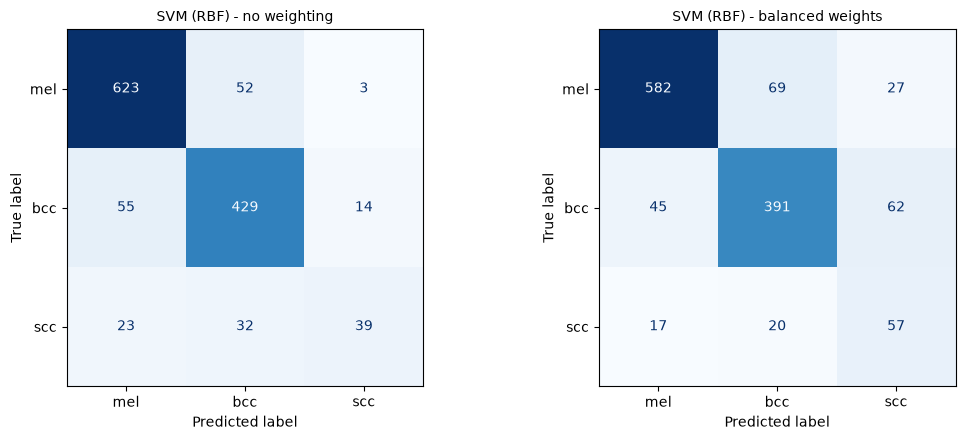

In [9]:
best = {exp: cv_bacc.loc[exp].idxmax() for exp in ["no weighting", "balanced weights"]}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (exp, m) in zip(axes, best.items()):
    plot_confusion(ax, y_val, predictions[(exp, m)], f"{m} - {exp}", class_names=MULTI_CLASS_NAMES.values())
plt.tight_layout()
plt.show()

## 4. Save the best model

In [10]:
best_key = cv_bacc.idxmax()
row = val_results.set_index(["experiment", "model"]).loc[best_key]
print("Best by CV:", best_key)

joblib.dump({
    "model":        fitted[best_key],             # scaler + classifier, trained on the whole train set
    "experiment":   best_key[0],
    "model_name":   best_key[1],
    "feature_cols": feature_cols,
    "class_names":  MULTI_CLASS_NAMES,
    "cv_scores":    cv_results.set_index(["experiment", "model"]).loc[best_key].to_dict(),
    "val_scores":   row.drop("cv_balanced_accuracy").to_dict(),
}, MODELS_DIR / "multi_baseline_v1.joblib")

Best by CV: ('balanced weights', 'SVM (RBF)')


['C:\\Users\\david\\OneDrive\\Documentos\\GitHub\\Project-1-CAD\\models\\multi_baseline_v1.joblib']

## 5. Summary on the validation set
Kappa and accuracy of each class (= recall: % of the images of that class that are classified correctly) of the 6 models,
before balancing (no weighting) and after balancing (balanced class weights).

In [2]:
val_table = pd.read_csv(RESULTS_DIR / "multi_val_baseline.csv")
cv_table = pd.read_csv(RESULTS_DIR / "multi_cv_baseline.csv")

versions = {"no weighting": "Before balancing", "balanced weights": "After balancing"}
columns = {"kappa": "Kappa", **{f"recall_{n}": f"Acc. {n}" for n in MULTI_CLASS_NAMES.values()}}
summary = (val_table.replace({"experiment": versions})
           .pivot(index="model", columns="experiment", values=list(columns))
           .rename(columns=columns)
           .swaplevel(axis=1)
           .reindex(columns=pd.MultiIndex.from_product([versions.values(), columns.values()]))
           .loc[val_table["model"].unique()])
summary.index.name = None
display(summary.round(3))

# Best model = highest CV balanced accuracy (the validation set is never used to choose)
best_exp, best_model = cv_table.loc[cv_table["balanced_accuracy"].idxmax(), ["experiment", "model"]]
best_row = val_table[(val_table["experiment"] == best_exp) & (val_table["model"] == best_model)].iloc[0]
print(f"Best model (highest CV balanced accuracy): {best_model} - {versions[best_exp].lower()}")
print(f"  Validation kappa:    {best_row['kappa']:.3f}")
print(f"  Validation accuracy: {best_row['accuracy']:.3f}")

# For reference: which model gets the highest value of each metric on validation
for metric in ["kappa", "accuracy"]:
    top = val_table.loc[val_table[metric].idxmax()]
    print(f"Highest validation {metric}: {top['model']} - {versions[top['experiment']].lower()} ({top[metric]:.3f})")

Before balancing                            After balancing  \
                         Kappa Acc. mel Acc. bcc Acc. scc           Kappa   
LogReg                   0.631    0.860    0.831    0.213           0.549   
Random Forest            0.657    0.885    0.863    0.085           0.663   
HistGradBoost            0.702    0.903    0.882    0.170           0.698   
SVM (RBF)                0.741    0.919    0.861    0.415           0.670   
XGBoost                  0.714    0.906    0.882    0.223           0.653   
CatBoost                 0.691    0.906    0.861    0.181           0.647   

                                          
              Acc. mel Acc. bcc Acc. scc  
LogReg           0.782    0.675    0.649  
Random Forest    0.853    0.867    0.277  
HistGradBoost    0.892    0.865    0.277  
SVM (RBF)        0.858    0.785    0.606  
XGBoost          0.845    0.817    0.447  
CatBoost         0.844    0.807    0.457

Best model (highest CV balanced accuracy): SVM (RBF) - after balancing
  Validation kappa:    0.670
  Validation accuracy: 0.811
Highest validation kappa: SVM (RBF) - before balancing (0.741)
Highest validation accuracy: SVM (RBF) - before balancing (0.859)


## Conclusions
- Without balancing, all models almost ignore scc (accuracy of scc 0.09-0.42 on validation), although the global accuracy and kappa look high.
- Balanced class weights raise the scc accuracy and the balanced accuracy of every model, at the cost of some mel/bcc accuracy, so global accuracy and kappa drop slightly.
- Best model by CV balanced accuracy: **SVM (RBF) with balanced weights**, the same as in the binary problem (validation: balanced accuracy 0.750, kappa 0.670).
  If the official metric were kappa, the unweighted SVM would be preferred (kappa 0.741, but scc accuracy only 0.415).
- Main remaining error: bcc and scc are confused with each other; better features (computed inside the lesion) are the next step.